# Final-state Manhattan estimate and action-model feature projections

This notebook uses only the final state from each random walk. It computes Manhattan distance and hidden features from the action model for the same sampled final states, then plots eight random projection histograms with sample counts and average Manhattan distance coloring. Run training first so the configured checkpoint is available.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from config import CONFIG_PATH, load_config
from fifteen_puzzle import PuzzleWalkDataset
from solve import load_model

In [2]:
config = load_config()
dataset_path = config["dataset"]["save_path"]

if dataset_path:
    dataset_path = Path(dataset_path)
    if not dataset_path.is_absolute():
        dataset_path = CONFIG_PATH.parent / dataset_path

if dataset_path and dataset_path.exists():
    with np.load(dataset_path) as saved:
        dataset = PuzzleWalkDataset(
            saved["states"],
            saved["moves"],
            saved["path_ids"],
            saved["steps"],
        )
else:
    dataset = PuzzleWalkDataset.generate(
        paths=config["walk"]["paths"],
        length=config["walk"]["T"],
        seed=config["seed"],
    )

final_indices = np.flatnonzero(dataset.steps == config["walk"]["T"])
sample_count = min(5000, len(final_indices))
rng = np.random.default_rng(config["seed"] + 1)
sample_indices = rng.choice(final_indices, size=sample_count, replace=False)
sampled_states = dataset.states[sample_indices]

In [3]:
def manhattan_distance(state):
    distance = 0
    for position, tile in enumerate(state):
        if tile == 0:
            continue
        goal_position = int(tile) - 1
        row, column = divmod(position, 4)
        goal_row, goal_column = divmod(goal_position, 4)
        distance += abs(row - goal_row) + abs(column - goal_column)
    return distance

estimated_distances = np.asarray(
    [manhattan_distance(state) for state in sampled_states],
    dtype=np.float32,
)
model = load_model(config)
device = next(model.parameters()).device
states_tensor = torch.as_tensor(sampled_states.astype(np.int64), device=device)

with torch.inference_mode():
    embeddings = model.features(states_tensor)
embedding_norms = torch.linalg.vector_norm(embeddings, ord=2, dim=1).cpu().numpy()

len(sampled_states), estimated_distances[:5], embedding_norms[:5]

(5000,
 array([30., 36., 40., 34., 22.], dtype=float32),
 array([2.719545 , 5.4671926, 3.720839 , 2.8524745, 3.5043113],
       dtype=float32))

/var/folders/s9/ffg0bh2s6cd2lsyw3vbc1yww0000gn/T/ipykernel_53866/499564284.py:76: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


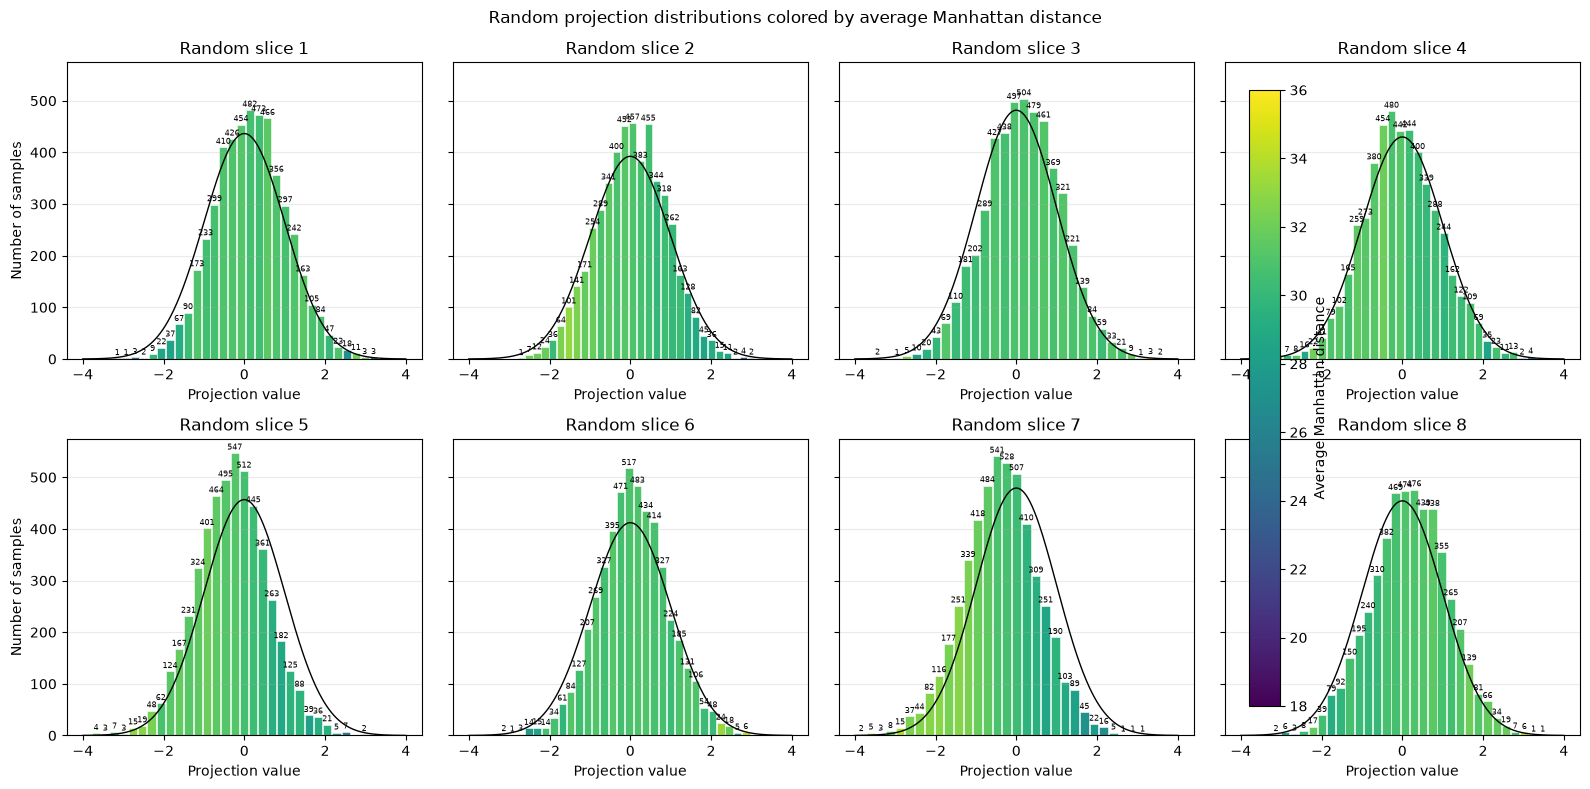

In [4]:
embedding_matrix = embeddings.cpu().numpy()
slice_count = 8
slice_rng = np.random.default_rng(config["seed"] + 2)
directions = slice_rng.normal(size=(embedding_matrix.shape[1], slice_count))
directions /= np.linalg.norm(directions, axis=0, keepdims=True)
projected_slices = embedding_matrix @ directions
bin_count = 30
normal_x = np.linspace(-4, 4, 400)
normal_density = np.exp(-0.5 * normal_x**2) / np.sqrt(2 * np.pi)
projection_bins = []

for slice_index in range(slice_count):
    values = projected_slices[:, slice_index]
    lower = float(values.min())
    upper = float(values.max())
    if np.isclose(lower, upper):
        bin_edges = np.linspace(lower - 0.5, upper + 0.5, bin_count + 1)
    else:
        bin_edges = np.linspace(lower, upper, bin_count + 1)
    bin_ids = np.digitize(values, bin_edges[1:-1])
    counts = np.bincount(bin_ids, minlength=bin_count)
    distance_sums = np.bincount(
        bin_ids, weights=estimated_distances, minlength=bin_count
    )
    average_distances = np.divide(
        distance_sums,
        counts,
        out=np.zeros_like(distance_sums),
        where=counts > 0,
    )
    nonempty = counts > 0
    projection_bins.append(
        (values, bin_edges, counts, average_distances, nonempty)
    )

color_values = np.concatenate(
    [averages[nonempty] for _, _, _, averages, nonempty in projection_bins]
)
cmap = plt.colormaps["viridis"]
color_scale = plt.Normalize(vmin=color_values.min(), vmax=color_values.max())
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey=True)

for slice_index, (ax, item) in enumerate(zip(axes.flat, projection_bins)):
    values, bin_edges, counts, average_distances, nonempty = item
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    bin_widths = np.diff(bin_edges)
    bar_colors = cmap(color_scale(average_distances[nonempty]))
    bars = ax.bar(
        bin_centers[nonempty],
        counts[nonempty],
        width=bin_widths[nonempty] * 0.9,
        color=bar_colors,
        edgecolor="white",
        linewidth=0.4,
    )
    ax.bar_label(
        bars,
        labels=[str(int(count)) for count in counts[nonempty]],
        padding=1,
        fontsize=6,
    )
    expected_counts = normal_density * len(values) * bin_widths.mean()
    ax.plot(normal_x, expected_counts, color="black", linewidth=1)
    ax.set_title(f"Random slice {slice_index + 1}")
    ax.set_xlabel("Projection value")
    ax.grid(axis="y", alpha=0.25)

axes[0, 0].set_ylabel("Number of samples")
axes[1, 0].set_ylabel("Number of samples")
fig.suptitle("Random projection distributions colored by average Manhattan distance")
colorbar = fig.colorbar(
    plt.cm.ScalarMappable(norm=color_scale, cmap=cmap),
    ax=axes.ravel().tolist(),
)
colorbar.set_label("Average Manhattan distance")
fig.tight_layout()
plt.show()

In [5]:
slice_index = 0
projection_values = projected_slices[:, slice_index]
bin_edges = projection_bins[slice_index][1]

if bin_edges[0] <= 0 <= bin_edges[-1]:
    center_bin = np.searchsorted(bin_edges, 0, side="right") - 1
    center_bin = min(center_bin, len(bin_edges) - 2)
    lower_edge = bin_edges[center_bin]
    upper_edge = bin_edges[center_bin + 1]
    in_center_bin = (projection_values >= lower_edge) & (projection_values < upper_edge)
    distances, counts = np.unique(
        estimated_distances[in_center_bin].astype(int),
        return_counts=True,
    )
    print(f"Random slice {slice_index + 1}, center bin [{lower_edge:.3f}, {upper_edge:.3f})")
    print(f"Samples in center bin: {int(in_center_bin.sum())}")
    for distance, count in zip(distances, counts):
        print(f"Manhattan estimate {distance}: {count} samples")
else:
    print("The sampled projection range does not include zero.")

Random slice 1, center bin [-0.192, 0.027)
Samples in center bin: 454
Manhattan estimate 18: 2 samples
Manhattan estimate 20: 12 samples
Manhattan estimate 22: 19 samples
Manhattan estimate 24: 26 samples
Manhattan estimate 26: 40 samples
Manhattan estimate 28: 51 samples
Manhattan estimate 30: 61 samples
Manhattan estimate 32: 74 samples
Manhattan estimate 34: 65 samples
Manhattan estimate 36: 40 samples
Manhattan estimate 38: 40 samples
Manhattan estimate 40: 13 samples
Manhattan estimate 42: 8 samples
Manhattan estimate 44: 1 samples
Manhattan estimate 46: 1 samples
Manhattan estimate 52: 1 samples


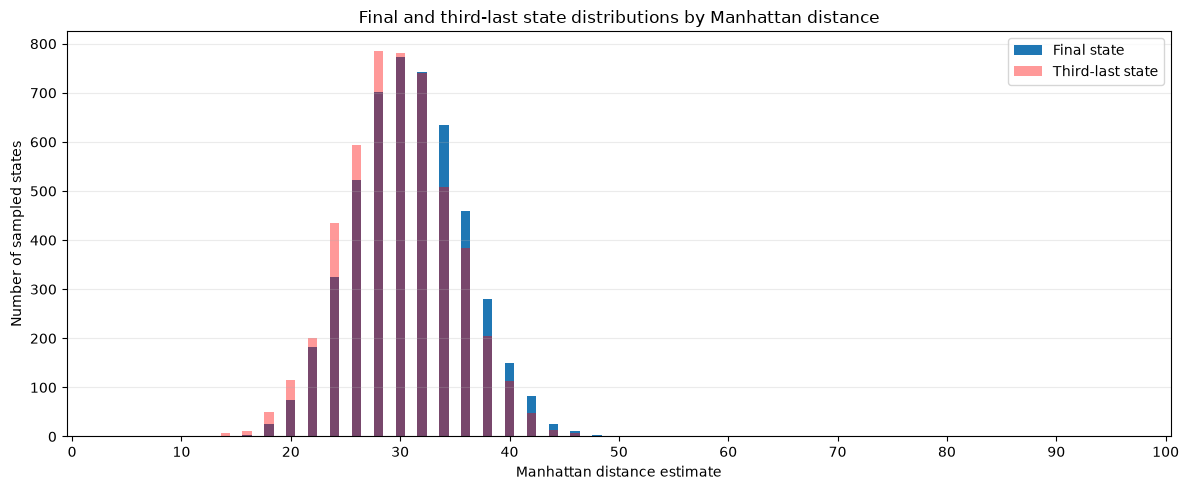

In [6]:
distance_values = np.arange(101)
final_counts = np.bincount(
    estimated_distances.astype(int),
    minlength=101,
)[:101]
sampled_path_ids = dataset.path_ids[sample_indices]
third_last_mask = (
    (dataset.steps == config["walk"]["T"] - 10)
    & np.isin(dataset.path_ids, sampled_path_ids)
)
third_last_indices = np.flatnonzero(third_last_mask)
third_last_distances = np.asarray(
    [manhattan_distance(state) for state in dataset.states[third_last_indices]],
    dtype=int,
)
third_last_counts = np.bincount(third_last_distances, minlength=101)[:101]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(
    distance_values,
    final_counts,
    width=0.85,
    label="Final state",
)
ax.bar(
    distance_values,
    third_last_counts,
    width=0.85,
    color="red",
    alpha=0.4,
    label="Third-last state",
)
ax.set_xlabel("Manhattan distance estimate")
ax.set_ylabel("Number of sampled states")
ax.set_title("Final and third-last state distributions by Manhattan distance")
ax.set_xlim(-0.5, 100.5)
ax.set_xticks(np.arange(0, 101, 10))
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

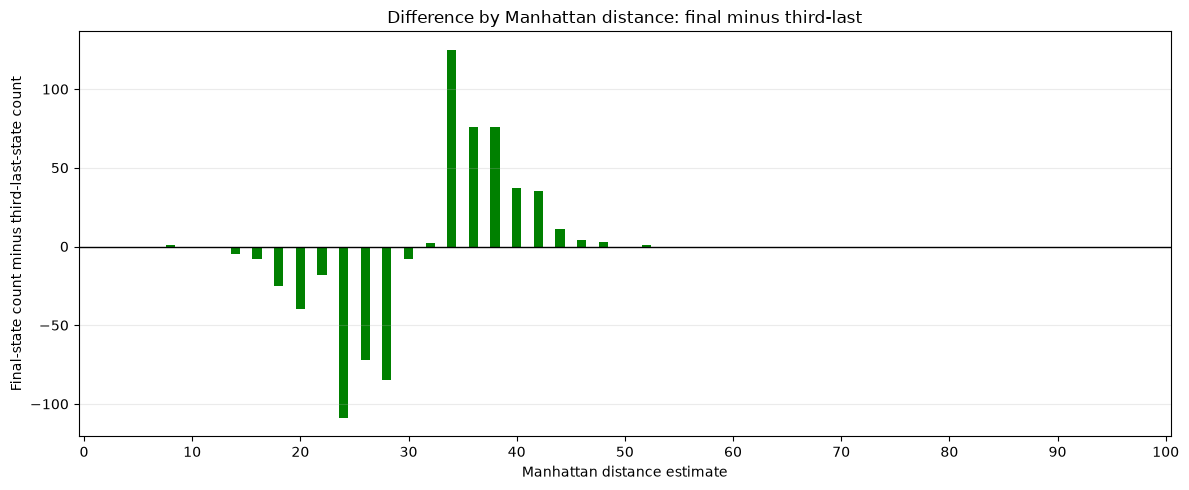

In [7]:
difference_counts = final_counts - third_last_counts

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(distance_values, difference_counts, width=0.85, color="green")
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Manhattan distance estimate")
ax.set_ylabel("Final-state count minus third-last-state count")
ax.set_title("Difference by Manhattan distance: final minus third-last")
ax.set_xlim(-0.5, 100.5)
ax.set_xticks(np.arange(0, 101, 10))
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()